# U04-A05 — Oficina — Relatório exploratório

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_04/04_oficina_relatorio_exploratorio.ipynb)

## O que será produzido

Nesta atividade integrada, você reunirá os resultados dos Notebooks 01, 02 e 03
em um **relatório exploratório curto e auditável**. O relatório deve apresentar o
que existe na base, destacar padrões e casos que merecem leitura próxima e formular
hipóteses provisórias. Ele não deve apresentar testes estatísticos nem tratar padrões
descritivos como conclusões históricas.

Este notebook é deliberadamente discursivo: execute ou adapte os cálculos em seu
notebook técnico e registre aqui as escolhas, resultados e interpretações em células
Markdown. Você pode trabalhar com os 24 registros fictícios da unidade ou com uma
base própria já preparada segundo as Unidades 2 e 3.

**Entrega esperada:** um relatório com escopo, perfil quantitativo, perfil textual,
quatro visualizações acompanhadas de tabelas, retorno a três casos, até três
hipóteses, limitações e instruções de reprodução.

A entrega esperada enumera os componentes do relatório. Para que eles não se
tornem partes isoladas, a oficina usa uma ordem em que cada resultado fornece a
base para a decisão seguinte.

## Como realizar a oficina

![Pergunta, tabela, figura, leitura e limite formam uma cadeia; divergências exigem revisão.](imagens/04_cadeia_argumento.svg)

Siga esta ordem:

1. declare a pergunta, o corpus e a unidade de análise;
2. selecione somente medidas pertinentes às variáveis e à pergunta;
3. produza tabelas antes de interpretar gráficos;
4. descreva o padrão observado sem explicar sua causa;
5. retorne a documentos ou trechos que possam qualificar o agregado;
6. formule hipóteses alternativas e indique dados necessários para avaliá-las;
7. registre limites e verifique se outra pessoa consegue reproduzir os resultados.

Para cada resultado, use a sequência abaixo:

- **Procedimento:** o que foi calculado, sobre quais registros e com qual regra?
- **Descrição:** que valores ou padrões aparecem?
- **Interpretação:** que leitura situada pode ser considerada?
- **Limite:** o que esse resultado não permite afirmar?
- **Próximo passo:** que caso, dado ou método deveria ser examinado?

Evite frases como “o gráfico prova”. Prefira “nesta base”, “o padrão observado” e
“uma hipótese a investigar”.

A sequência anterior funciona como um protocolo geral. Sua aplicação começa
pela delimitação: antes de calcular ou visualizar, é necessário saber quais casos
estão incluídos e o que cada linha permite observar.

## 1. Escopo e qualidade da base

### O que fazer

- formule uma pergunta exploratória compatível com os dados disponíveis;
- identifique corpus, período, unidade de análise e quantidade de registros;
- classifique as variáveis que serão utilizadas;
- informe ausências, erros conhecidos, cobertura e casos extremos;
- explique por que a base é adequada — ou apenas parcialmente adequada — à pergunta.

### O que entregar

| Elemento | Resposta |
|---|---|
| **Pergunta exploratória** | Como a palavra *liberdade* é empregada e com que termos aparece associada nos discursos de posse presidencial brasileiros entre 1985 e 2023? |
| **Corpus e período** | 12 discursos de posse, 1985–2023 (Sarney, Collor, Itamar, FHC ×2, Lula ×3, Dilma ×2, Temer, Bolsonaro). 39.069 tokens. Fonte: repositório `estadao/discurso-de-posse-presidentes` (até 2003 derivado de *Palavra de Presidente*, de João Bosco Bezerra Bonfim; depois, acervo do Estadão e Biblioteca da Presidência); o discurso de 2023 foi fornecido pelo autor do projeto. |
| **Unidade de análise** | Duas, articuladas por `id_doc`: o **discurso** (`documentos_processaveis.csv`, 12 linhas) e o **trecho** com ocorrência de `liberdade(s)` (`discursos_trechos.csv`, 49 linhas) — sentença-alvo mais uma sentença à esquerda e uma à direita. |
| **Variáveis e escalas** | `presidente`, `tipo_discurso`, `termo_coocorrente` → categóricas nominais; `ano` → temporal (data); `palavras`, `ocorrencias_liberdade`, `frequencia` → numéricas de razão; `taxa_liberdade_mil` e `ttr` → razões derivadas; `id_doc` e `trecho_id` → identificadores, não medidas. |
| **Cobertura e ausências** | Cobertura completa dos mandatos iniciados entre 1985 e 2023. `partido` está integralmente nulo, com `razao_partido_ausente` (não verificado em fonte documental). Três discursos têm `ocorrencias_liberdade = 0`, com `razao_ausencia` preenchida — ausência observada, não dado faltante. Exclusões em `motivos_exclusao.csv`: Tancredo Neves (não tomou posse) e os 24 discursos anteriores a 1985 (fora do recorte). |
| **Erros conhecidos e casos extremos** | Só o arquivo de 2023 preserva quebras de parágrafo, o que forçou a segmentação por sentença em todo o corpus. Sarney (1985) e Temer (2016) são casos limítrofes: nenhum proferiu o texto na sessão solene de posse. Extremos de extensão pela regra de 1,5·IQR: Collor (5.917 palavras) e Itamar (614). |
| **Adequação e principal limite** | A base responde a *onde e com que companhia lexical o termo aparece*; não responde a *o que cada presidente quis dizer*. Com n = 12 e 55 ocorrências, nenhuma diferença entre períodos comporta teste ou generalização. |

Não descreva apenas o arquivo. Explique a relação entre a pergunta e aquilo que cada
linha efetivamente representa.

In [1]:
import math
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

docs = pd.read_csv("dados/derivados/documentos_processaveis.csv").sort_values("ano")
trechos = pd.read_csv("dados/derivados/discursos_trechos.csv")
coocorrencias = pd.read_csv("dados/derivados/coocorrencias.csv")

CURTO = {"José Sarney": "Sarney", "Fernando Collor de Mello": "Collor",
         "Itamar Franco": "Itamar", "Fernando Henrique Cardoso": "FHC",
         "Luiz Inácio Lula da Silva": "Lula", "Dilma Rousseff": "Dilma",
         "Michel Temer": "Temer", "Jair Bolsonaro": "Bolsonaro"}
docs["curto"] = docs["presidente"].map(CURTO)
rotulos = docs["ano"].astype(str) + "\n" + docs["curto"]

TOKEN = re.compile(r"[a-záàâãéêíóôõúüçñ]+")
ALVO = {"liberdade", "liberdades"}
docs["tokens"] = [TOKEN.findall((open(f"dados/brutos/{a}", encoding="utf-8").read()).lower())
                  for a in docs["arquivo_bruto"]]

print("discursos:", len(docs), "| trechos:", len(trechos),
      "| tokens do corpus:", sum(docs["tokens"].map(len)))
docs[["ano", "curto", "palavras", "ocorrencias_liberdade",
      "taxa_liberdade_mil", "n_trechos"]]

discursos: 12 | trechos: 49 | tokens do corpus: 39069


,ano,curto,palavras,ocorrencias_liberdade,taxa_liberdade_mil,n_trechos
0,1985,Sarney,3860,19,4.922280,16
1,1990,Collor,5917,9,1.521041,8
2,1992,Itamar,614,0,0.000000,0
3,1995,FHC,3255,8,2.457757,7
4,1999,FHC,2703,1,0.369959,1
5,2003,Lula,3881,0,0.000000,0
6,2007,Lula,3833,0,0.000000,0
7,2011,Dilma,3828,4,1.044932,4
8,2015,Dilma,4523,3,0.663277,2
9,2016,Temer,2741,1,0.364830,1


Com corpus, unidade e qualidade declarados, já podemos produzir descrições
numéricas compatíveis com o alcance da base. Os limites identificados na seção
anterior devem acompanhar a leitura de cada medida.

## 2. Perfil quantitativo

### O que fazer

1. apresente ao menos uma frequência absoluta e a proporção correspondente;
2. escolha uma variável quantitativa e calcule medidas de centro e dispersão;
3. examine sua distribuição e os limites de 1,5 IQR;
4. inspecione os registros sinalizados, sem removê-los automaticamente;
5. construa uma tabela de contingência com contagens e proporções por linha;
6. separe descrição, interpretação e hipótese.

In [2]:
# (a) frequência e proporção: discursos que mencionam o termo
docs["menciona"] = docs["ocorrencias_liberdade"].gt(0).map(
    {True: "menciona", False: "não menciona"})
frequencia = docs["menciona"].value_counts().rename("frequencia")
proporcao = docs["menciona"].value_counts(normalize=True).rename("proporcao").round(3)
display(pd.concat([frequencia, proporcao], axis=1))

# (b) centro e dispersão de `palavras` (ddof=1, quartis por interpolação linear)
x = docs["palavras"]
q1, q3 = x.quantile(.25), x.quantile(.75)
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
display(pd.Series({
    "n": x.count(), "media": round(x.mean(), 1), "mediana": x.median(),
    "desvio_padrao_ddof1": round(x.std(ddof=1), 1),
    "q1": q1, "q3": q3, "iqr": iqr,
    "limite_inferior": round(limite_inferior), "limite_superior": round(limite_superior),
}, name="palavras"))

# (c) registros sinalizados pela regra de 1,5 IQR — inspecionados, não removidos
display(docs.loc[x.lt(limite_inferior) | x.gt(limite_superior),
                 ["id_doc", "palavras", "ocorrencias_liberdade", "taxa_liberdade_mil"]])

# (d) contingência: período × intensidade de uso
docs["periodo"] = docs["ano"].map(
    lambda a: "1985-1995" if a <= 1995 else ("1999-2007" if a <= 2007 else "2011-2023"))
docs["classe_uso"] = docs["taxa_liberdade_mil"].map(
    lambda t: "sem menção" if t == 0 else ("até 1/mil" if t <= 1 else "acima de 1/mil"))
ordem = ["sem menção", "até 1/mil", "acima de 1/mil"]
display(pd.crosstab(docs["periodo"], docs["classe_uso"])[ordem])
display(pd.crosstab(docs["periodo"], docs["classe_uso"], normalize="index")[ordem].round(3))

,frequencia,proporcao
menciona,,
menciona,9,0.75
não menciona,3,0.25


n                        12.00
media                  3243.30
mediana                3541.50
desvio_padrao_ddof1    1431.80
q1                     2685.50
q3                     3865.25
iqr                    1179.75
limite_inferior         916.00
limite_superior        5635.00
Name: palavras, dtype: float64

,id_doc,palavras,ocorrencias_liberdade,taxa_liberdade_mil
1,DISCURSO_1990_COLLOR,5917,9,1.521041
2,DISCURSO_1992_ITAMAR,614,0,0.000000


classe_uso,sem menção,até 1/mil,acima de 1/mil
periodo,,,
1985-1995,1,0,3
1999-2007,2,1,0
2011-2023,0,2,3


classe_uso,sem menção,até 1/mil,acima de 1/mil
periodo,,,
1985-1995,0.250,0.000,0.75
1999-2007,0.667,0.333,0.00
2011-2023,0.000,0.400,0.60


### Evidências mínimas

| Resultado | Denominador ou convenção | Valor observado | Leitura e limite |
|---|---|---|---|
| frequência/proporção | n = 12 discursos | 9 mencionam o termo (0,75); 3 não mencionam (0,25) | a ausência é observada, não faltante; mas o lexema não esgota o tema — Lula 2007 usa `livre` 3× sem usar `liberdade` |
| centro e dispersão | `palavras`, `ddof=1`, quartis por interpolação linear | média 3.243,3; mediana 3.541,5; dp 1.431,8; Q1 2.685,5; Q3 3.865,3; IQR 1.179,8 | média abaixo da mediana indica assimetria à esquerda puxada por Itamar; a dispersão inviabiliza comparar contagens brutas entre discursos |
| caso extremo | limites [916; 5.635] | Collor 1990 (5.917) e Itamar 1992 (614) | os dois são documentalmente explicáveis, não erros de contagem; nenhum foi removido |
| contingência | total de cada linha (4, 3 e 5 discursos) | 1985–1995: 0,75 acima de 1/mil; 1999–2007: 0,67 sem menção; 2011–2023: 0,60 acima de 1/mil e 0 sem menção | distribuição em U; com 3 a 5 discursos por linha, uma única mudança de documento altera a proporção |

### Exemplo do nível de escrita esperado

> **Descrição:** D023 possui 2.100 palavras e é o único registro acima do limite
> superior de 1,5 IQR. **Interpretação:** ele pode representar um documento
> efetivamente mais extenso ou uma diferença de registro. **Limite:** a regra não
> demonstra erro e não justifica exclusão. **Próximo passo:** conferir a fonte e o
> procedimento de contagem de D023.

**Minha análise quantitativa**

- **Procedimento:** contagem de `liberdade(s)` por regex `\bliberdades?\b` sobre os 12 discursos normalizados; medidas de centro e dispersão sobre `palavras` com `ddof=1`; regra de 1,5·IQR; contingência período × classe de uso, com proporções por linha.
- **Descrição:** 55 ocorrências em 39.069 tokens (1,41 por mil no corpus inteiro), muito desigualmente distribuídas: 19 estão em 1985. Três discursos têm zero. A extensão varia de 614 a 5.917 palavras. A contingência mostra uso alto nas pontas do período e concentração de ausências entre 1999 e 2007.
- **Interpretação:** nesta base, o termo se comporta como vocabulário de conjuntura — associado à transição de 1985 e ao período recente — e não como item estável do gênero de posse.
- **Limite:** n = 12; a forma em U pode ser efeito de composição do corpus (um discurso por posse) e da própria extensão dos textos; nada aqui é teste de diferença.
- **Próximo passo:** normalizar por extensão (Figura 3) e examinar o entorno do termo, já que a contagem não distingue sentidos.

O perfil quantitativo descreve composição, extensão e cruzamentos, mas não
mostra como os temas são formulados nos textos. A exploração textual acrescenta
essa camada sem abandonar os IDs, denominadores e limites já estabelecidos.

## 3. Perfil textual

### O que fazer

- documente tokenização, conversão para minúsculas, pontuação e stopwords;
- apresente frequências absolutas e relativas com denominador explícito;
- escolha um termo relevante e examine concordâncias com identificador documental;
- apresente bigramas e PMI com frequência mínima declarada;
- compare TTR bruta e TTR em segmentos de tamanho comum;
- retorne ao texto sempre que uma contagem ou colocação parecer substantivamente
  importante.

In [3]:
# (a) tokenização e frequências, com os dois denominadores declarados
STOPWORDS = {"a", "o", "os", "as", "um", "uma", "de", "do", "da", "dos", "das", "e", "é",
             "em", "no", "na", "nos", "nas", "que", "com", "por", "para", "se", "ao",
             "aos", "à", "às", "não", "sua", "seu", "mais", "como", "mas", "ou", "nossa",
             "nosso", "esta", "este", "isso", "sem", "ser", "foi", "já", "também"}
todos = [t for ts in docs["tokens"] for t in ts]
conteudo = [t for t in todos if t not in STOPWORDS]
ocorrencias_alvo = sum(1 for t in todos if t in ALVO)
display(pd.Series({
    "N_todos_tokens": len(todos), "N_tokens_conteudo": len(conteudo),
    "formas_distintas": len(set(todos)), "ocorrencias_liberdade": ocorrencias_alvo,
    "relativa_por_mil_todos": round(ocorrencias_alvo / len(todos) * 1000, 3),
    "relativa_por_mil_conteudo": round(ocorrencias_alvo / len(conteudo) * 1000, 3),
}, name="corpus"))

# (b) concordâncias: janela de 5 tokens, com identificador documental
def concordancias(janela=5):
    linhas = []
    for linha in docs.itertuples():
        for pos, token in enumerate(linha.tokens):
            if token in ALVO:
                ini, fim = max(0, pos - janela), min(len(linha.tokens), pos + janela + 1)
                linhas.append({"id_doc": linha.id_doc,
                               "contexto": " ".join(linha.tokens[ini:fim])})
    return pd.DataFrame(linhas)

kwic = concordancias()
display(kwic.groupby("id_doc").head(1).head(9))

# (c) bigramas e PMI, frequência mínima 2, restritos ao termo-alvo
bigramas, esquerda, direita = Counter(), Counter(), Counter()
for ts in docs["tokens"]:
    pares = list(zip(ts, ts[1:]))
    bigramas.update(pares); esquerda.update(a for a, _ in pares); direita.update(b for _, b in pares)
N_bigramas = sum(bigramas.values())
linhas_pmi = [(f"{a} {b}", f, math.log2(f * N_bigramas / (esquerda[a] * direita[b])))
              for (a, b), f in bigramas.items()
              if f >= 2 and (a in ALVO or b in ALVO)]
display(pd.DataFrame(sorted(linhas_pmi, key=lambda l: -l[2]),
                     columns=["bigrama", "frequencia", "pmi"]).round(2).head(6))

# (d) TTR bruta e padronizada em segmento comum
m = int(docs["tokens"].map(len).min())
docs["ttr_padronizada"] = docs["tokens"].map(lambda ts: len(set(ts[:m])) / m)
print("tamanho comum adotado (m):", m, "tokens")
display(docs[["ano", "curto", "palavras", "ttr", "ttr_padronizada"]].round(3))

N_todos_tokens               39069.000
N_tokens_conteudo            23610.000
formas_distintas              6360.000
ocorrencias_liberdade           55.000
relativa_por_mil_todos           1.408
relativa_por_mil_conteudo        2.330
Name: corpus, dtype: float64

,id_doc,contexto
0,DISCURSO_1985_SARNEY,o brasil mudou respira se liberdade volta se a...
19,DISCURSO_1990_COLLOR,em toda parte penhor da liberdade e evidência ...
28,DISCURSO_1995_FHC,o crescimento mas sacrificaram a liberdade tro...
36,DISCURSO_1999_FHC,o país desfruta de plena liberdade de opinião ...
37,DISCURSO_2011_DILMA,moderna plena de compromisso social liberdade ...
41,DISCURSO_2015_DILMA,da constituição das leis das liberdades indivi...
44,DISCURSO_2016_TEMER,desvios nesse contexto tomo a liberdade de diz...
45,DISCURSO_2019_BOLSONARO,pátria da ordem e da liberdade tentaram pôr fi...
48,DISCURSO_2023_LULA,as mais violentas ameaças à liberdade do voto ...


,bigrama,frequencia,pmi
0,liberdades individuais,3,12.03
1,as liberdades,4,6.32
2,liberdade econômica,3,6.12
3,das liberdades,2,5.95
4,liberdade política,4,5.13
5,à liberdade,3,3.75


tamanho comum adotado (m): 621 tokens


,ano,curto,palavras,ttr,ttr_padronizada
0,1985,Sarney,3860,0.370,0.564
1,1990,Collor,5917,0.335,0.546
2,1992,Itamar,614,0.526,0.527
3,1995,FHC,3255,0.378,0.531
4,1999,FHC,2703,0.401,0.567
5,2003,Lula,3881,0.371,0.556
6,2007,Lula,3833,0.359,0.533
7,2011,Dilma,3828,0.333,0.491
8,2015,Dilma,4523,0.319,0.490
9,2016,Temer,2741,0.370,0.533


### Evidências mínimas

| Etapa | Regra ou parâmetro | Resultado selecionado | Interpretação e limite |
|---|---|---|---|
| tokenização/normalização | minúsculas; `re.findall(r"[a-záàâãéêíóôõúüçñ]+")`; pontuação e números descartados; tokenização **por documento**, para não criar bigramas entre o fim de um discurso e o início do seguinte | 39.069 tokens, 6.360 formas distintas | a regra une `liberdade` e `Liberdade` e separa formas hifenizadas; `livre` e `livremente` ficam fora do alvo por decisão, não por acidente |
| frequências | N = 39.069 (todos os tokens); N_c após stopwords, para a tabela de conteúdo | 55 ocorrências de `liberdade(s)` = 1,408 por mil tokens | a taxa do corpus esconde a concentração em 1985; por isso a taxa por documento é calculada separadamente |
| concordância | termo `liberdade/liberdades`, janela ±5 tokens, `id_doc` preservado | 55 janelas; em 2023, `a liberdade que eles pregam é a de oprimir o vulnerável` | o retorno ao texto mostra o termo em disputa explícita, algo que nenhuma contagem registra; a janela corta orações longas |
| colocação | bigramas com o termo, frequência mínima 2, PMI em log₂ | `liberdades individuais` PMI 12,03 (f = 3); `liberdade econômica` 6,12 (f = 3); `liberdade política` 5,13 (f = 4) | PMI alto com f = 3 é frágil por construção: a medida favorece eventos raros; a leitura só se sustenta junto das concordâncias |
| diversidade | m = 621 tokens (menor documento, Itamar 1992); primeiros m tokens | TTR bruta 0,319–0,526; TTR padronizada 0,490–0,567 | a TTR bruta ordena os discursos quase pelo inverso do tamanho; padronizada, a variação quase desaparece — a diversidade aparente era efeito de extensão |

Uma lista de palavras não constitui interpretação. Explique como as regras de
processamento condicionam o que aparece no resultado.

**Meu perfil textual**

- **Procedimento:** tokenização por documento; frequências com denominador declarado; 55 concordâncias com janela ±5; bigramas com o termo-alvo e PMI (f ≥ 2); TTR bruta e padronizada em m = 621 tokens.
- **Descrição:** o termo aparece 1,41 vezes por mil tokens no corpus. Os bigramas de maior PMI são `liberdades individuais`, `liberdade econômica` e `liberdade política`. A TTR bruta vai de 0,319 (Dilma 2015) a 0,526 (Itamar 1992); padronizada, fica entre 0,490 e 0,567.
- **Interpretação:** o termo quase nunca aparece sozinho — vem qualificado por um adjetivo ou por um complemento (`de expressão`, `de culto`, `de empreender`). É nesse complemento, e não na frequência, que a variação entre períodos se manifesta.
- **Limite:** com f = 3 ou 4, PMI é instável; a lista de stopwords é minha e altera a tabela de conteúdo; a TTR padronizada usa os primeiros 621 tokens, que em discurso de posse são majoritariamente vocativos protocolares.
- **Próximo passo:** classificar manualmente os 49 trechos por tipo de liberdade invocada (civil, política, econômica, de expressão), com dupla codificação — a coocorrência automática sugere, mas não decide.

Os perfis quantitativo e textual fornecem vários resultados possíveis. A etapa
seguinte não consiste em desenhar todos eles, mas em selecionar aqueles que melhor
respondem à pergunta e comunicá-los sem romper a ligação com as tabelas.

## 4. Visualizações

### O que fazer

Produza **quatro visualizações**, escolhendo famílias adequadas às perguntas e
variáveis. Uma combinação possível é: barras categóricas, histograma ou boxplot,
dispersão ou série temporal e barras de frequências textuais.

| Pergunta | Visual recomendado | O que deve acompanhar |
|---|---|---|
| como categorias se distribuem? | barras | contagens/proporções e denominador |
| como uma quantitativa se distribui? | histograma e/ou boxplot | intervalos, quartis e casos sinalizados |
| como duas quantitativas variam juntas? | dispersão | tabela dos pares e aviso de não causalidade |
| como um agregado muda por ano? | linha | tamanho e composição de cada grupo anual |
| quais termos são frequentes? | barras | tabela ordenada e regra de tokenização |

Para **cada figura**, entregue:

1. pergunta respondida e justificativa do tipo de gráfico;
2. título informativo, escalas e unidades;
3. tabela equivalente aos valores representados;
4. descrição alternativa acessível;
5. descrição do padrão e identificação de pelo menos um caso;
6. interpretação situada e limite.

As quatro figuras estão nas células seguintes, cada uma acompanhada da sua tabela
equivalente e da análise correspondente. São as mesmas selecionadas no Notebook 03.

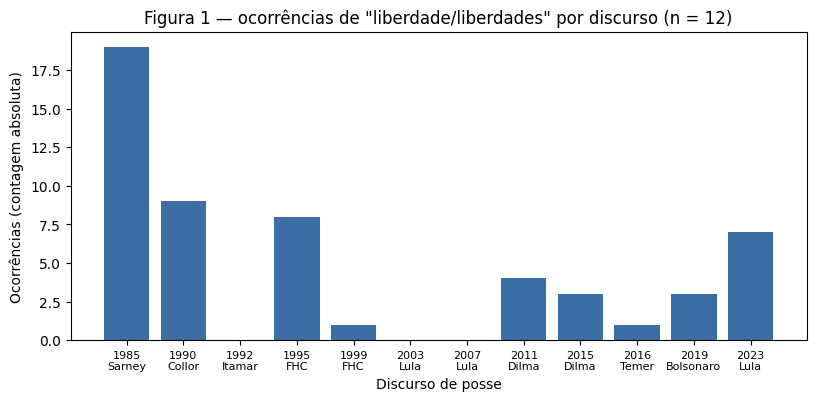

,ano,curto,palavras,ocorrencias_liberdade,n_trechos,razao_ausencia
0,1985,Sarney,3860,19,16,NaN
1,1990,Collor,5917,9,8,NaN
2,1992,Itamar,614,0,0,pronunciamento sem menção ao termo
3,1995,FHC,3255,8,7,NaN
4,1999,FHC,2703,1,1,NaN
5,2003,Lula,3881,0,0,pronunciamento sem menção ao termo
6,2007,Lula,3833,0,0,pronunciamento sem menção ao termo
7,2011,Dilma,3828,4,4,NaN
8,2015,Dilma,4523,3,2,NaN
9,2016,Temer,2741,1,1,NaN


In [4]:
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.bar(rotulos, docs["ocorrencias_liberdade"], color="#3b6ea5")
ax.set_title('Figura 1 — ocorrências de "liberdade/liberdades" por discurso (n = 12)')
ax.set_xlabel("Discurso de posse"); ax.set_ylabel("Ocorrências (contagem absoluta)")
ax.tick_params(axis="x", labelsize=8)
plt.show()

docs[["ano", "curto", "palavras", "ocorrencias_liberdade", "n_trechos", "razao_ausencia"]]

**Figura 1 — análise**

| Item | Conteúdo |
|---|---|
| Pergunta e justificativa | Em quais discursos o termo aparece? Barras comparam unidades discretas e tornam a ausência visível como altura zero — uma linha a interpolaria. |
| Escalas e unidades | Eixo x categórico (discurso, ordem cronológica); eixo y numérico de razão, contagem absoluta. |
| Tabela equivalente | Acima: ano, presidente, palavras, ocorrências, trechos e `razao_ausencia`. |
| Descrição alternativa | Doze barras verticais em ordem cronológica; 1985 é a mais alta, com 19; 1992, 2003 e 2007 têm altura zero; as demais ficam entre 1 e 9. |
| Padrão e caso | 1985 concentra 19 das 55 ocorrências. Caso: Lula, zero em 2003 e 2007 e 7 em 2023 — o mesmo presidente, comportamento oposto. |
| Interpretação e limite | O uso do termo parece ligado à conjuntura, não ao locutor. Limite: contagem absoluta não é comparável entre textos de tamanhos diferentes, e a ausência do lexema não é ausência do tema. |

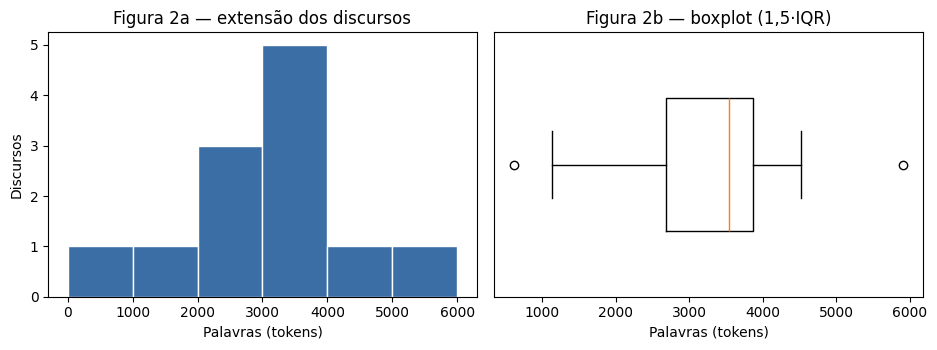

palavras
(0, 1000]       1
(1000, 2000]    1
(2000, 3000]    3
(3000, 4000]    5
(4000, 5000]    1
(5000, 6000]    1
Name: discursos, dtype: int64

,id_doc,palavras
1,DISCURSO_1990_COLLOR,5917
2,DISCURSO_1992_ITAMAR,614


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.6))
a1.hist(docs["palavras"], bins=range(0, 7000, 1000), color="#3b6ea5", edgecolor="white")
a1.set_title("Figura 2a — extensão dos discursos")
a1.set_xlabel("Palavras (tokens)"); a1.set_ylabel("Discursos")
a2.boxplot(docs["palavras"], vert=False, widths=.5)
a2.set_title("Figura 2b — boxplot (1,5·IQR)")
a2.set_xlabel("Palavras (tokens)"); a2.set_yticks([])
plt.tight_layout(); plt.show()

faixas = pd.cut(docs["palavras"], bins=range(0, 7000, 1000))
display(docs.groupby(faixas, observed=False).size().rename("discursos"))
docs.loc[docs["palavras"].lt(limite_inferior) | docs["palavras"].gt(limite_superior),
         ["id_doc", "palavras"]]

**Figura 2 — análise**

| Item | Conteúdo |
|---|---|
| Pergunta e justificativa | Os discursos são comparáveis em tamanho? Histograma mostra a forma da distribuição; o boxplot acrescenta a regra explícita de 1,5·IQR para sinalizar casos. |
| Escalas e unidades | `palavras`, numérica de razão, discreta; intervalos de 1.000 tokens. |
| Tabela equivalente | Contagem por faixa e lista dos registros fora dos limites [916; 5.635]. |
| Descrição alternativa | Histograma com a maior barra na faixa de 3.000 a 4.000 palavras e caudas dos dois lados; boxplot horizontal com dois pontos fora dos whiskers. |
| Padrão e caso | Variação de quase 10×, de 614 a 5.917 palavras. Caso: Itamar 1992, com 614 palavras — o zero da Figura 1 tem base textual mínima. |
| Interpretação e limite | A heterogeneidade de extensão obriga a normalizar antes de comparar contagens. Limite: a regra de 1,5·IQR sinaliza, não demonstra erro; nenhum dos dois extremos foi excluído. |

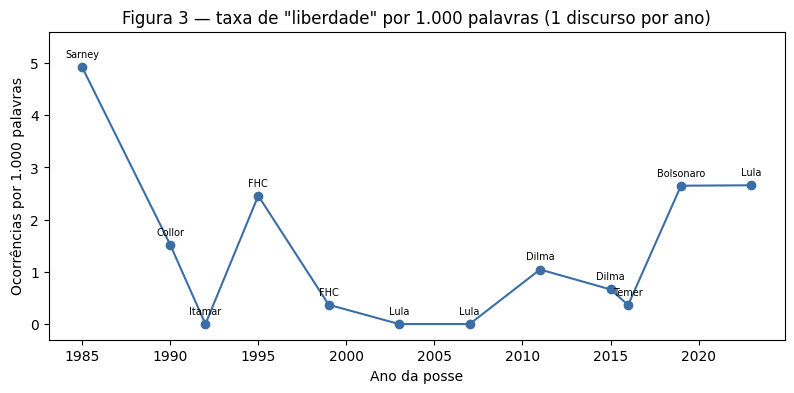

,ano,curto,palavras,ocorrencias_liberdade,taxa_liberdade_mil
0,1985,Sarney,3860,19,4.922
1,1990,Collor,5917,9,1.521
2,1992,Itamar,614,0,0.000
3,1995,FHC,3255,8,2.458
4,1999,FHC,2703,1,0.370
5,2003,Lula,3881,0,0.000
6,2007,Lula,3833,0,0.000
7,2011,Dilma,3828,4,1.045
8,2015,Dilma,4523,3,0.663
9,2016,Temer,2741,1,0.365


In [6]:
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(docs["ano"], docs["taxa_liberdade_mil"], marker="o", color="#3b6ea5")
for _, r in docs.iterrows():
    ax.annotate(r["curto"], (r["ano"], r["taxa_liberdade_mil"]),
                textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7)
ax.set_title('Figura 3 — taxa de "liberdade" por 1.000 palavras (1 discurso por ano)')
ax.set_xlabel("Ano da posse"); ax.set_ylabel("Ocorrências por 1.000 palavras")
ax.set_ylim(-.3, 5.6)
plt.show()

docs[["ano", "curto", "palavras", "ocorrencias_liberdade", "taxa_liberdade_mil"]].round(3)

**Figura 3 — análise**

| Item | Conteúdo |
|---|---|
| Pergunta e justificativa | Controlada a extensão, como o uso se distribui no tempo? A linha ordena cronologicamente e a taxa corrige o viés diagnosticado na Figura 2. |
| Escalas e unidades | Eixo x temporal, discreto e irregular (anos de posse); eixo y em ocorrências por 1.000 palavras. |
| Tabela equivalente | Acima: ano, presidente, palavras (denominador), ocorrências e taxa. Cada ponto é **um** discurso, não uma média anual. |
| Descrição alternativa | Linha com marcadores: 4,92 em 1985, queda a 0 em 1992, 2,46 em 1995, platô próximo de zero entre 1999 e 2007, subida a 2,65 em 2019 e 2,66 em 2023. |
| Padrão e caso | Forma em U. Caso: 2019 e 2023 quase empatam na taxa (2,650 e 2,659) com contagens bem diferentes (3 e 7), porque Bolsonaro fala 1.132 palavras e Lula 2.633. |
| Interpretação e limite | O uso reaparece nas duas pontas do período democrático. Limite: a linha liga anos não contíguos e sugere continuidade que 12 pontos não sustentam. |

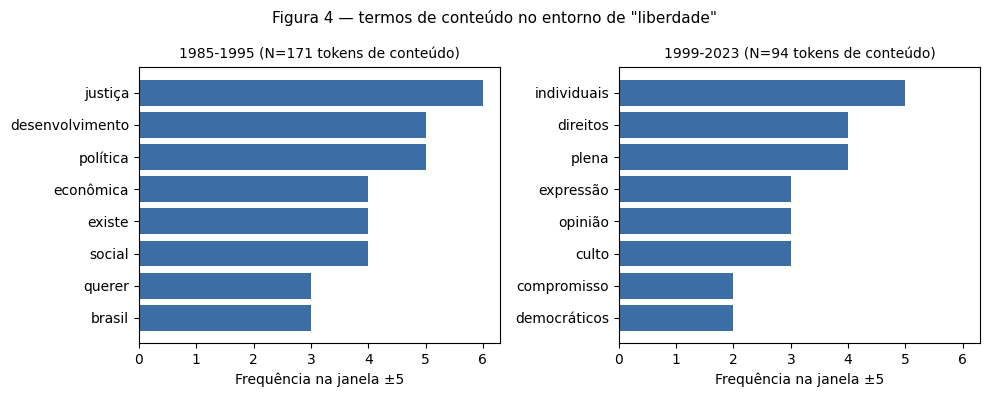

,periodo,termo_coocorrente,frequencia
66,1985-1995,justiça,6
24,1985-1995,desenvolvimento,5
89,1985-1995,política,5
33,1985-1995,econômica,4
44,1985-1995,existe,4
117,1985-1995,social,4
102,1985-1995,querer,3
7,1985-1995,brasil,3
161,1999-2023,individuais,5
151,1999-2023,direitos,4


In [7]:
coocorrencias["periodo"] = coocorrencias["ano"].map(
    lambda a: "1985-1995" if a <= 1995 else "1999-2023")
tabela_coo = (coocorrencias.groupby(["periodo", "termo_coocorrente"])["frequencia"]
              .sum().reset_index().sort_values("frequencia", ascending=False))
denominadores = coocorrencias.groupby("periodo")["frequencia"].sum()
top = {p: tabela_coo[tabela_coo["periodo"] == p].head(8) for p in ["1985-1995", "1999-2023"]}

fig, eixos = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for eixo, periodo in zip(eixos, top):
    d = top[periodo].iloc[::-1]
    eixo.barh(d["termo_coocorrente"], d["frequencia"], color="#3b6ea5")
    eixo.set_title(f"{periodo} (N={int(denominadores[periodo])} tokens de conteúdo)", fontsize=10)
    eixo.set_xlabel("Frequência na janela ±5")
fig.suptitle('Figura 4 — termos de conteúdo no entorno de "liberdade"', fontsize=11)
plt.tight_layout(); plt.show()

pd.concat([top["1985-1995"], top["1999-2023"]])

**Figura 4 — análise**

| Item | Conteúdo |
|---|---|
| Pergunta e justificativa | Com que campo semântico o termo aparece associado em cada período? Barras horizontais preservam o valor exato e acomodam rótulos longos, ao contrário da nuvem de palavras. |
| Escalas e unidades | Frequência absoluta por termo nominal, dentro da janela ±5 tokens, após remoção de stopwords. |
| Tabela equivalente | Oito termos por período, com os denominadores N = 171 (1985–1995) e N = 94 (1999–2023). |
| Descrição alternativa | Dois painéis de barras horizontais: à esquerda, `justiça` (6), `desenvolvimento` (5), `política` (5); à direita, `individuais` (5), `direitos` (4), `plena` (4), `expressão` (3), `opinião` (3), `culto` (3). |
| Padrão e caso | O entorno migra de vocabulário socioeconômico e de regime para vocabulário de direitos individuais enumerados. Caso: Dilma 2011 enumera `liberdades individuais`, `de culto e de religião`, `de imprensa e de opinião` em sequência, e sozinha responde por boa parte do painel direito. |
| Interpretação e limite | A ressignificação se manifesta no complemento do termo, não na frequência. Limite: frequências baixíssimas (máximo 6), janela que corta sintagmas e partição em dois períodos decidida por mim, não pela fonte. |

As visualizações tornam padrões mais perceptíveis, mas também comprimem
diferenças e retiram documentos de seu contexto. Por isso, todo padrão selecionado
deve orientar um retorno deliberado a casos que possam confirmá-lo, contradizê-lo
ou qualificá-lo.

## 5. Retorno aos casos

![Agregados orientam a seleção de casos; a leitura próxima retorna para revisar categorias, contagens, hipóteses e limites.](imagens/04_ciclo_agregados_casos.svg)

### O que fazer

Escolha três casos que ajudem a compreender, contradizer ou qualificar os agregados.
Inclua obrigatoriamente um caso extremo ou inesperado e pelo menos um trecho textual.
Não selecione apenas exemplos que confirmem sua primeira interpretação.

In [8]:
for id_doc in ["DISCURSO_2023_LULA", "DISCURSO_1992_ITAMAR", "DISCURSO_1985_SARNEY"]:
    print(f"--- {id_doc} | palavras={int(docs.loc[docs.id_doc == id_doc, 'palavras'].iloc[0])} "
          f"| ocorrências={int(docs.loc[docs.id_doc == id_doc, 'ocorrencias_liberdade'].iloc[0])}")
    for r in trechos[trechos.id_doc == id_doc].head(3).itertuples():
        print(f"  [{r.trecho_id}] {r.sentenca_alvo[:140]}")

--- DISCURSO_2023_LULA | palavras=2633 | ocorrências=7
  [DISCURSO_2023_LULA_SENT_005] as mais violentas ameaças à liberdade do voto, a mais abjeta campanha de mentiras e de ódio tramada para manipular e constranger o eleitorad
  [DISCURSO_2023_LULA_SENT_047] A outra, no individualismo, na negação da política, na destruição do Estado em nome de supostas liberdades individuais.
  [DISCURSO_2023_LULA_SENT_048] A liberdade que sempre defendemos é a de viver com dignidade, com pleno direito de expressão, manifestação e organização.
--- DISCURSO_1992_ITAMAR | palavras=614 | ocorrências=0
--- DISCURSO_1985_SARNEY | palavras=3860 | ocorrências=19
  [DISCURSO_1985_SARNEY_SENT_003] Respira-se liberdade.
  [DISCURSO_1985_SARNEY_SENT_057] Nossos objetivos passam por cinco pontos fundamentais: Liberdade Desenvolvimento Opção social Identidade cultural Soberania e Independência 
  [DISCURSO_1985_SARNEY_SENT_058] A liberdade é um legado de Deus.


| Caso/ID | Por que foi escolhido? | Evidência documental ou trecho | O que muda na leitura do agregado? |
|---|---|---|---|
| **DISCURSO_2023_LULA** (caso inesperado) | Fecha a série e tem a maior taxa do período recente (2,66/mil, 7 ocorrências) | `A liberdade que eles pregam é a de oprimir o vulnerável, massacrar o oponente e impor a lei do mais forte` — e, logo antes, `a negação da política, na destruição do Estado em nome de supostas liberdades individuais` | O agregado trata toda ocorrência como uso do conceito; aqui o termo é **disputado**, usado para recusar o sentido atribuído ao adversário. Coocorrência alta com `individuais` não indica adesão a esse sentido — indica polêmica sobre ele. |
| **DISCURSO_1992_ITAMAR** (caso extremo) | Único discurso com zero ocorrências e simultaneamente o mais curto (614 palavras), fora do limite inferior de 1,5·IQR | Discurso inteiro de 614 palavras, proferido na posse após o impeachment de Collor | O zero na Figura 1 não é escolha lexical: é efeito de um pronunciamento mínimo. A ausência deveria ser lida como não-evidência, e não como evidência de recuo do conceito. |
| **DISCURSO_1985_SARNEY** (caso que sustenta o agregado) | Máximo absoluto e relativo do corpus (19 ocorrências, 4,92/mil) | `Respira-se liberdade.` · `A liberdade é um legado de Deus.` · `As leis dão ordem ao exercício da liberdade.` · `Nossos objetivos passam por cinco pontos fundamentais: Liberdade Desenvolvimento Opção social...` | Confirma o pico, mas qualifica-o: parte das ocorrências vem de uma **lista programática** e de formulações aforísticas, não de argumentação distribuída ao longo do texto. O pico é também um efeito de gênero retórico. |

O objetivo é praticar o movimento entre leitura distante e leitura próxima, não
usar três exemplos isolados como prova do comportamento de todo o corpus.

Depois do retorno aos casos, algumas leituras iniciais serão reforçadas e
outras precisarão ser revistas. Somente nesse ponto os padrões agregados e as
evidências documentais podem alimentar hipóteses — ainda provisórias e abertas a
explicações alternativas.

## 6. Hipóteses provisórias

Formule no máximo três hipóteses. Cada uma deve permanecer compatível com o caráter
exploratório desta unidade.

| Hipótese provisória | Evidência exploratória | Explicação alternativa | Dados adicionais necessários | Método futuro |
|---|---|---|---|---|
| **H1.** A diferença observada entre períodos pode estar associada ao **complemento** do termo, e não à sua frequência: de liberdade como condição do regime para liberdade como lista de direitos enumeráveis | Figura 4: `justiça`, `desenvolvimento`, `política` (1985–1995) contra `individuais`, `direitos`, `expressão`, `culto` (1999–2023); bigrama `liberdades individuais` com PMI 12,03 | Convenção do gênero: enumerar direitos pode ser praxe de posse pós-Constituição de 1988, independente de projeto político | Discursos de posse estaduais e mensagens anuais ao Congresso, para verificar se a enumeração é praxe institucional | Codificação manual dos trechos por tipo de liberdade, com dupla codificação e medida de concordância |
| **H2.** O uso do termo pode estar associado a **conjunturas de disputa sobre o regime**, e não ao presidente ou ao partido | Forma em U da Figura 3: picos em 1985 e 2019–2023, vale em 1999–2007; Lula registra 0, 0 e 7 em três posses | Efeito de extensão e de estilo do redator: discursos curtos e programáticos concentram mais o vocabulário | Séries de pronunciamentos ao longo de cada mandato, não apenas as posses | Comparação de taxas entre gêneros discursivos do mesmo governo |
| **H3.** Em 2023 o termo pode estar funcionando como **objeto de disputa** e não como valor afirmado | Trechos `a liberdade que eles pregam...` e `supostas liberdades individuais`, ambos com marcação de distanciamento | Recurso retórico pontual de um único discurso, sem continuidade | Discursos de 2023 em diante e pronunciamentos do campo adversário no mesmo período | Análise de polaridade e de marcadores de atribuição de voz nos trechos |

Uma hipótese adequada poderia começar com “A diferença observada pode estar
associada a...”. Não use “comprovamos”, “é significativo” ou linguagem causal sem
desenho e evidência apropriados.

Uma hipótese exploratória só é intelectualmente útil quando suas fronteiras
podem ser examinadas. A próxima seção registra tanto os limites da evidência
quanto o percurso necessário para que outra pessoa reconstrua os resultados.

## 7. Limitações e reprodutibilidade

### Limitações

Responda explicitamente:

- que grupos, períodos ou tipos de documento podem estar sub-representados?
- que escolhas de limpeza, tokenização ou agregação afetam os resultados?
- que padrões podem resultar da construção fictícia ou institucional da base?
- quais conclusões não devem ser formuladas?

**Limitações do relatório**

- **Sub-representação.** Só o chefe do Executivo federal, só no rito de posse. Oposição, Legislativo, movimentos sociais e governos estaduais estão fora. O gênero é conciliador por convenção e tende a suavizar disputas.
- **Escolhas que afetam o resultado.** A regex `\bliberdades?\b` exclui `livre`, `livremente` e `libertário`; a janela ±5 corta sintagmas longos; a lista de stopwords é minha; a partição 1985–1995 / 1999–2023 é analítica, não documental; e a segmentação por sentença substituiu a segmentação por parágrafo prevista no protocolo, porque só o arquivo de 2023 preserva parágrafos.
- **Construção institucional da base.** As transcrições são de terceiros (livro e acervo jornalístico), não do registro oficial primário; o texto de 2023 vem de origem diferente dos demais. Sarney (1985) e Temer (2016) entram como casos limítrofes, por não terem proferido o texto na sessão solene de posse.
- **Conclusões que não devem ser formuladas.** Que houve mudança ideológica demonstrada; que a diferença entre períodos é estatisticamente significativa; que a ausência do termo indica ausência do tema; que o discurso de posse representa o pensamento do governo ou da sociedade.

### Reprodutibilidade

Outra pessoa deve conseguir identificar:

- arquivo e versão da entrada;
- ambiente e dependências;
- ordem dos notebooks ou células;
- parâmetros alterados, como stopwords, janela, frequência mínima e bins;
- tabelas que sustentam cada gráfico;
- caminho entre agregado, ID e documento.

**Instruções para reproduzir**

1. **Entradas.** `dados/brutos/`: 12 arquivos `.txt` imutáveis, `metadados_discursos.csv` e `proveniencia_base_publica.json` (fonte, endereço, data de acesso 2026-09-17, recorte e ressalvas).
2. **Ambiente.** Python 3.12, `pandas` 3.0, `matplotlib` 3.10; bibliotecas padrão `pathlib`, `re`, `json`, `unicodedata`, `collections`.
3. **Ordem de execução.** `01_ingestao.py` → `02_base_processavel.py` → `03_figuras.py` → este notebook. Nenhuma etapa edita arquivos brutos.
4. **Parâmetros alteráveis.** alvo `\bliberdades?\b`; janela de coocorrência ±5; `STOPWORDS`; frequência mínima de PMI = 2; `bins` do histograma de 1.000 em 1.000; corte de período em 1995; `m` da TTR padronizada = menor documento (621).
5. **Tabelas que sustentam cada figura.** Fig. 1 e 3 → `documentos_processaveis.csv`; Fig. 2 → mesma tabela, coluna `palavras`; Fig. 4 → `coocorrencias.csv`.
6. **Caminho do agregado ao documento.** agregado → `id_doc` → `trecho_id` (com `posicao_sentenca` e `total_sentencas`) → `dados/brutos/<id_doc>.txt`. As regras aplicadas estão em `dados/intermediarios/log_transformacoes.csv`; as exclusões, em `dados/derivados/motivos_exclusao.csv`.

Agora já existem resultados, interpretações, hipóteses e limites. Organizar o
relatório significa transformar esses elementos em uma cadeia de evidência que o
leitor consiga seguir da pergunta até as condições de reprodução.

## 8. Estrutura do relatório final

Organize a entrega nesta ordem:

1. pergunta, corpus, unidade e qualidade da base;
2. perfil quantitativo;
3. perfil textual;
4. quatro visualizações com tabelas equivalentes;
5. retorno aos três casos;
6. hipóteses provisórias e alternativas;
7. limitações;
8. instruções de reprodução;
9. referências utilizadas.

O relatório pode ser entregue neste notebook preenchido ou em documento equivalente,
desde que preserve essas evidências e a ligação com o notebook técnico.

A estrutura define o que o relatório precisa conter; a dinâmica define como
produzi-lo dentro do tempo da aula. A revisão por pares verificará se a cadeia é
compreensível para alguém que não acompanhou todas as decisões do autor.

## U04-A06 — 9. Dinâmica sugerida e revisão por pares

Para uma aula de quatro horas, a meta é produzir uma primeira versão completa do
relatório. Os cálculos básicos já devem ter sido executados nos Notebooks 01 a 03.

| Tempo | Trabalho |
|---:|---|
| 20 min | definir pergunta, unidade e diagnóstico da base |
| 40 min | selecionar resultados quantitativos e conferir denominadores |
| 15 min | pausa |
| 40 min | selecionar resultados textuais e retornar a concordâncias |
| 40 min | escolher quatro visualizações e suas tabelas equivalentes |
| 15 min | pausa |
| 30 min | selecionar três casos e formular hipóteses alternativas |
| 20 min | revisão por um colega |
| 20 min | incorporar correções, limites e instruções de reprodução |

O colega revisor deve conseguir responder: “Qual é a unidade?”, “Qual é o
denominador?”, “Que caso sustenta ou contradiz a leitura?”, “O gráfico possui tabela e
descrição?” e “A hipótese está apresentada como provisória?”.

**Parecer recebido:** pendente — a revisão por pares ainda não foi realizada.

**Mudanças realizadas após a revisão:** pendente, aguardando o parecer.

O parecer do colega fornece uma leitura externa, mas a entrega ainda precisa de
critérios comuns de qualidade. A rubrica traduz as exigências do percurso em itens
que orientam a última revisão do relatório.

## 10. Rubrica e checklist de entrega

Avalie cada critério de 0 a 2. Use 0 para ausente ou inadequado, 1 para parcial e 2
para completo e justificável.

| Critério | 0 | 1 | 2 | Minha nota e evidência |
|---|---|---|---|---|
| escopo e qualidade | não definidos | parciais | pergunta, unidade, cobertura e limites coerentes | **2** — duas unidades declaradas, exclusões registradas em `motivos_exclusao.csv`, casos limítrofes identificados |
| correção quantitativa | cálculos inadequados | resultados sem convenções | medidas, denominadores e extremos verificados | **2** — `ddof=1`, quartis por interpolação linear, limites de 1,5·IQR explícitos, extremos inspecionados sem remoção |
| exploração textual | regras ausentes | resultados sem contexto | regras, métricas e concordâncias documentadas | **2** — tokenização por documento, dois denominadores, 55 concordâncias com `id_doc`, PMI com frequência mínima, TTR padronizada |
| visualização e acessibilidade | gráficos inadequados | documentação parcial | quatro figuras com tabela e descrição | **2** — quatro figuras, cada uma com tabela equivalente e descrição alternativa |
| retorno aos casos | ausente | casos apenas confirmatórios | três casos que qualificam agregados | **2** — 2023 contradiz a leitura da coocorrência, 1992 explica o zero, 1985 confirma mas qualifica o pico |
| hipóteses e limites | conclusão indevida | limites genéricos | hipóteses alternativas e limites específicos | **2** — três hipóteses provisórias, cada uma com explicação alternativa e dados necessários |
| reprodutibilidade | percurso desconhecido | instruções incompletas | entradas, parâmetros e ordem reconstruíveis | **1** — scripts, parâmetros e log estão registrados, mas as versões de pacotes não estão fixadas em arquivo de ambiente |

**Total:** 13 de 14 pontos. O ponto perdido é de reprodutibilidade: falta um
`requirements.txt` com versões fixadas. A referência de aprovação é 11/14, sem zero
em correção quantitativa ou hipóteses e limites.

Antes de entregar, confirme: quatro visualizações, quatro tabelas equivalentes, três
casos, no máximo três hipóteses, limitações específicas, instruções de reprodução e
referências. A Unidade 5 tratará inferência; não acrescente significância estatística
sem que o método tenha sido estudado.

## 11. Referências utilizadas

1. BONFIM, João Bosco Bezerra. *Palavra de Presidente: os discursos presidenciais de posse, de Deodoro a Lula*. Brasília: Senado Federal, 2007. — fonte primária das transcrições até 2003.
2. D'IGNAZIO, Catherine; KLEIN, Lauren F. *Data Feminism*. Cambridge: MIT Press, 2020. — fundamenta o tratamento de silêncios e a declaração de escopo.
3. KOSELLECK, Reinhart. *Futuro Passado: contribuição à semântica dos tempos históricos*. Rio de Janeiro: Contraponto/PUC-Rio, 2006. — fundamenta a leitura de "liberdade" como conceito em disputa, base da H3.
4. RAWSON, Katie; MUÑOZ, Trevor. Against Cleaning. In: *Debates in the Digital Humanities*, 2019. — fundamenta o log de transformações e a recusa de exclusões automáticas.
5. STEVENS, S. S. On the Theory of Scales of Measurement. *Science*, 1946. — base da classificação de variáveis da seção 1.
6. Repositório `estadao/discurso-de-posse-presidentes`. — origem das transcrições legíveis por máquina; proveniência em `dados/brutos/proveniencia_base_publica.json`.